# 02 — Predicting 90-Day Repeat Purchases
## Who Deserves the Next Retention Dollar?

This notebook evaluates whether historical RFM behavior predicts a purchase within the next 90 days. Logistic regression provides an interpretable probability estimate, rather than an estimate of response to a retention offer.

## 1. Imports and chronological settings

March, June and September snapshots form the training, validation and test periods. Customers may appear in multiple snapshots, but the outcome windows do not overlap.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

OUTPUT = Path('outputs')
CLEAN_FILE = OUTPUT / '01_clean_purchase_lines.pkl'
if not CLEAN_FILE.exists():
    raise FileNotFoundError('Run Notebook 01 first; its cleaned transactions must be saved in outputs/.')

HISTORY_DAYS = 180
OUTCOME_DAYS = 90
TRAIN_DATE = pd.Timestamp('2011-03-01')
VALID_DATE = pd.Timestamp('2011-06-01')
TEST_DATE = pd.Timestamp('2011-09-10')  # Matches Notebook 01
FEATURES = ['RecencyDays', 'LogFrequency', 'LogMonetary']
print('Train:', TRAIN_DATE.date(), '| Validation:', VALID_DATE.date(), '| Test:', TEST_DATE.date())
print('Historical feature window:', HISTORY_DAYS, 'days | Future outcome:', OUTCOME_DAYS, 'days')

Train: 2011-03-01 | Validation: 2011-06-01 | Test: 2011-09-10
Historical feature window: 180 days | Future outcome: 90 days


## 2. Load cleaned purchase records

The model uses the positive purchase records from Notebook 01 and counts distinct customer purchase days. The outcome does not account for matched returns.

In [2]:
sales = pd.read_pickle(CLEAN_FILE)
sales['InvoiceDate'] = pd.to_datetime(sales['InvoiceDate'])
sales['PurchaseDay'] = sales['InvoiceDate'].dt.normalize()
needed = {'Customer ID', 'Invoice', 'InvoiceDate', 'SalesGBP'}
assert needed.issubset(sales.columns), f'Missing columns: {needed - set(sales.columns)}'
assert sales['SalesGBP'].gt(0).all()
assert sales['Customer ID'].notna().all()
assert TEST_DATE + pd.Timedelta(days=OUTCOME_DAYS) <= sales['InvoiceDate'].max(), 'Test outcome window is not fully observed.'
print('Clean purchase lines:', f'{len(sales):,}')
print('Customer IDs:', f"{sales['Customer ID'].nunique():,}")
print('Transaction date range:', sales['InvoiceDate'].min(), 'to', sales['InvoiceDate'].max())

Clean purchase lines: 805,549
Customer IDs: 5,878
Transaction date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


## 3. Construct features and repeat-purchase outcomes

Recency uses all prior purchase history; frequency and monetary value use the preceding 180 days. Repeat90d equals 1 when a customer purchases after the snapshot and within 90 days. Customers without recent purchases retain zero frequency and spending. The log1p transformation retains zeros and reduces skew, and scaling is fitted on training data only.

In [3]:
def make_snapshot(transactions, snapshot, history_days=180, outcome_days=90):
    window_start = snapshot - pd.Timedelta(days=history_days)
    outcome_end = snapshot + pd.Timedelta(days=outcome_days)
    past = transactions.loc[transactions['InvoiceDate'] <= snapshot]
    recent = past.loc[past['InvoiceDate'] > window_start]
    future = transactions.loc[(transactions['InvoiceDate'] > snapshot) &
                              (transactions['InvoiceDate'] <= outcome_end)]

    customers = past.groupby('Customer ID').agg(
        LastPurchase=('InvoiceDate', 'max'),
        HistoricalSpendGBP=('SalesGBP', 'sum')
    )
    recent_rfm = recent.groupby('Customer ID').agg(
        Frequency=('PurchaseDay', 'nunique'),
        MonetaryGBP=('SalesGBP', 'sum')
    )
    customers = customers.join(recent_rfm, how='left')
    customers[['Frequency', 'MonetaryGBP']] = customers[['Frequency', 'MonetaryGBP']].fillna(0)
    customers['Frequency'] = customers['Frequency'].astype(int)
    customers['RecencyDays'] = (snapshot - customers['LastPurchase']).dt.total_seconds() / 86400
    customers['LogFrequency'] = np.log1p(customers['Frequency'])
    customers['LogMonetary'] = np.log1p(customers['MonetaryGBP'])
    customers['Repeat90d'] = customers.index.isin(future['Customer ID'].unique()).astype(int)
    customers['SnapshotDate'] = snapshot
    result = customers.reset_index()
    assert result['Customer ID'].is_unique
    assert result['RecencyDays'].ge(0).all()
    assert (result['MonetaryGBP'] >= 0).all()
    return result

train = make_snapshot(sales, TRAIN_DATE, HISTORY_DAYS, OUTCOME_DAYS)
valid = make_snapshot(sales, VALID_DATE, HISTORY_DAYS, OUTCOME_DAYS)
test = make_snapshot(sales, TEST_DATE, HISTORY_DAYS, OUTCOME_DAYS)

snapshot_overview = pd.DataFrame([
    {'Set': name, 'Snapshot': frame['SnapshotDate'].iloc[0].date(),
     'Customers': len(frame), 'RepeatRatePct': 100*frame['Repeat90d'].mean(),
     'ZeroRecentOrders': int(frame['Frequency'].eq(0).sum())}
    for name, frame in [('Training', train), ('Validation', valid), ('Test', test)]
])
display(snapshot_overview.round(2))
assert TRAIN_DATE + pd.Timedelta(days=OUTCOME_DAYS) < VALID_DATE
assert VALID_DATE + pd.Timedelta(days=OUTCOME_DAYS) < TEST_DATE
assert len(test) == 5281, 'Test snapshot should match Notebook 01 (5,281 customers); verify inputs and settings.'
print('All test features are calculated as of the same snapshot used in Notebook 01.')
reference = pd.read_csv(OUTPUT / '01_customer_rfm_snapshot.csv')
check = test.merge(reference, on='Customer ID', suffixes=('_model', '_rfm'), validate='one_to_one')
assert len(check) == len(test) == len(reference)
for field in ['Frequency', 'RecencyDays', 'MonetaryGBP', 'HistoricalSpendGBP']:
    np.testing.assert_allclose(check[field + '_model'], check[field + '_rfm'])
print('Notebook 01 and 02 customer features agree.')


,Set,Snapshot,Customers,RepeatRatePct,ZeroRecentOrders
0,Training,2011-03-01,4537,34.98,1188
1,Validation,2011-06-01,4933,32.86,2274
2,Test,2011-09-10,5281,43.36,2494


All test features are calculated as of the same snapshot used in Notebook 01.
Notebook 01 and 02 customer features agree.


## 4. Logistic regression

The model uses three RFM predictors and a fixed 0.50 classification threshold. Coefficients and preprocessing are estimated from the training snapshot.

In [4]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
model.fit(train[FEATURES], train['Repeat90d'])
valid_prob = model.predict_proba(valid[FEATURES])[:, 1]
test_prob = model.predict_proba(test[FEATURES])[:, 1]

coef = model.named_steps['logisticregression'].coef_[0]
coef_table = pd.DataFrame({'Predictor': FEATURES,
                           'Coefficient': coef,
                           'OddsRatioPer1SD': np.exp(coef)})
display(coef_table.round(3))
print('Interpretation: odds ratios refer to a 1-standard-deviation increase in the')
print('model input, after the indicated log transformation for frequency and spending.')
print('Coefficients are associations, not effects of marketing offers.')

,Predictor,Coefficient,OddsRatioPer1SD
0,RecencyDays,-0.223,0.800
1,LogFrequency,1.244,3.470
2,LogMonetary,-0.334,0.716


Interpretation: odds ratios refer to a 1-standard-deviation increase in the
model input, after the indicated log transformation for frequency and spending.
Coefficients are associations, not effects of marketing offers.


## 5. Predictor correlation and temporal changes

Frequency and spending may be strongly correlated. Their regression coefficients represent conditional associations. Repeat-purchase prevalence is also compared across snapshots.

In [5]:
print('Training predictor correlation (Spearman):')
display(train[['RecencyDays', 'Frequency', 'MonetaryGBP']].corr(method='spearman').round(3))
print('Repeat rate and raw probability by snapshot:')
display(pd.DataFrame([
    {'Snapshot': 'March training', 'Customers': len(train), 'ActualRepeatRate': train['Repeat90d'].mean(), 'MeanPredicted': model.predict_proba(train[FEATURES])[:, 1].mean()},
    {'Snapshot': 'June validation', 'Customers': len(valid), 'ActualRepeatRate': valid['Repeat90d'].mean(), 'MeanPredicted': valid_prob.mean()},
    {'Snapshot': 'September test (diagnostic only)', 'Customers': len(test), 'ActualRepeatRate': test['Repeat90d'].mean(), 'MeanPredicted': test_prob.mean()}
]).round(3))
print('Interpretation: monetary coefficient is conditional on recency and frequency; it is not causal.')


Training predictor correlation (Spearman):


,RecencyDays,Frequency,MonetaryGBP
RecencyDays,1.000,-0.831,-0.761
Frequency,-0.831,1.000,0.898
MonetaryGBP,-0.761,0.898,1.000


Repeat rate and raw probability by snapshot:


,Snapshot,Customers,ActualRepeatRate,MeanPredicted
0,March training,4537,0.350,0.350
1,June validation,4933,0.329,0.286
2,September test (diagnostic only),5281,0.434,0.283


Interpretation: monetary coefficient is conditional on recency and frequency; it is not causal.


## 6. Validation-based probability adjustment

A constant log-odds intercept adjustment matches the mean prediction to the observed June repeat rate. The adjustment is selected only if June Brier score improves. It preserves ranking and is not a guarantee of full calibration. September outcomes are excluded from fitting the adjustment.

In [6]:
from scipy.special import expit, logit
from scipy.optimize import brentq

EPS = 1e-8
valid_log_odds = logit(np.clip(valid_prob, EPS, 1-EPS))
valid_observed = valid['Repeat90d'].mean()
intercept_shift = brentq(lambda shift: expit(valid_log_odds + shift).mean() - valid_observed, -20, 20)
valid_adjusted = expit(valid_log_odds + intercept_shift)
test_adjusted = expit(logit(np.clip(test_prob, EPS, 1-EPS)) + intercept_shift)

validation_brier_raw = brier_score_loss(valid['Repeat90d'], valid_prob)
validation_brier_adjusted = brier_score_loss(valid['Repeat90d'], valid_adjusted)
USE_ADJUSTED = validation_brier_adjusted < validation_brier_raw
final_test_prob = test_adjusted if USE_ADJUSTED else test_prob
final_valid_prob = valid_adjusted if USE_ADJUSTED else valid_prob

print(f'June intercept shift: {intercept_shift:+.3f} log-odds')
print(f'June Brier: raw={validation_brier_raw:.4f}, adjusted={validation_brier_adjusted:.4f}')
print('Selected using June only:', 'Adjusted probabilities' if USE_ADJUSTED else 'Original probabilities')
print('September Brier comparison (evaluation, not model selection):')
print(f'  Original={brier_score_loss(test["Repeat90d"], test_prob):.4f}')
print(f'  Adjusted={brier_score_loss(test["Repeat90d"], test_adjusted):.4f}')
print(f'  Selected={brier_score_loss(test["Repeat90d"], final_test_prob):.4f}')
print('ROC AUC unchanged by intercept shift:', round(roc_auc_score(test['Repeat90d'], final_test_prob), 3))


June intercept shift: +0.257 log-odds
June Brier: raw=0.1633, adjusted=0.1610
Selected using June only: Adjusted probabilities
September Brier comparison (evaluation, not model selection):
  Original=0.2138
  Adjusted=0.2023
  Selected=0.2023
ROC AUC unchanged by intercept shift: 0.775


## 7. Baseline comparison

The full model is compared with majority-class, recency-only and frequency-only baselines. Accuracy, precision and recall use a 0.50 threshold; ROC AUC and average precision evaluate ranking, while Brier score measures probability error. The full model receives the validation-based adjustment; the baselines are unadjusted.

In [7]:
recency_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
recency_model.fit(train[['RecencyDays']], train['Repeat90d'])

train_rate = train['Repeat90d'].mean()
majority_label = int(train_rate >= 0.5)

def metric_row(name, y, probability, threshold=0.5, probability_model=True):
    predicted = (np.asarray(probability) >= threshold).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y, predicted),
            'Precision': precision_score(y, predicted, zero_division=0),
            'Recall': recall_score(y, predicted, zero_division=0),
            'ROC_AUC': roc_auc_score(y, probability),
            'AveragePrecision': average_precision_score(y, probability),
            'Brier': brier_score_loss(y, probability) if probability_model else np.nan}

majority_prob = np.full(len(test), train_rate)
recency_prob = recency_model.predict_proba(test[['RecencyDays']])[:, 1]
frequency_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
frequency_model.fit(train[['LogFrequency']], train['Repeat90d'])
frequency_prob = frequency_model.predict_proba(test[['LogFrequency']])[:, 1]
results = pd.DataFrame([
    metric_row('Majority-class baseline', test['Repeat90d'], majority_prob),
    metric_row('Recency-only logistic', test['Repeat90d'], recency_prob),
    metric_row('Frequency-only logistic', test['Repeat90d'], frequency_prob),
    metric_row('RFM logistic regression (June-selected)', test['Repeat90d'], final_test_prob),
])
display(results.round(3))
print('Validation ROC AUC (RFM logistic):', round(roc_auc_score(valid['Repeat90d'], valid_prob), 3))
print('Test ROC AUC (RFM logistic):', round(roc_auc_score(test['Repeat90d'], final_test_prob), 3))
print('Training majority class:', majority_label, '(1=repeat, 0=no repeat)')

,Model,Accuracy,Precision,Recall,ROC_AUC,AveragePrecision,Brier
0,Majority-class baseline,0.566,0.000,0.000,0.500,0.434,0.253
1,Recency-only logistic,0.682,0.730,0.424,0.763,0.686,0.218
2,Frequency-only logistic,0.678,0.843,0.316,0.752,0.691,0.216
3,RFM logistic regression (June-selected),0.700,0.772,0.437,0.775,0.741,0.202


Validation ROC AUC (RFM logistic): 0.797
Test ROC AUC (RFM logistic): 0.775
Training majority class: 0 (1=repeat, 0=no repeat)


## 8. Confusion matrix and ROC curve

The confusion matrix summarizes classification outcomes at the fixed threshold. The ROC curve compares ranking performance with the recency-only baseline.

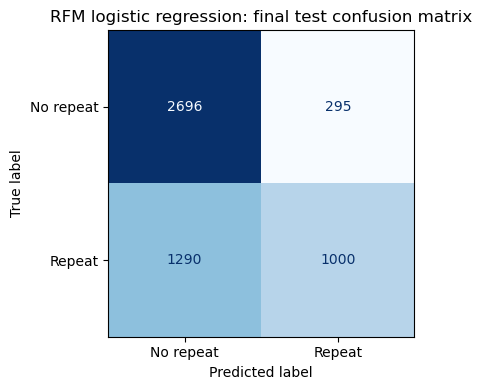

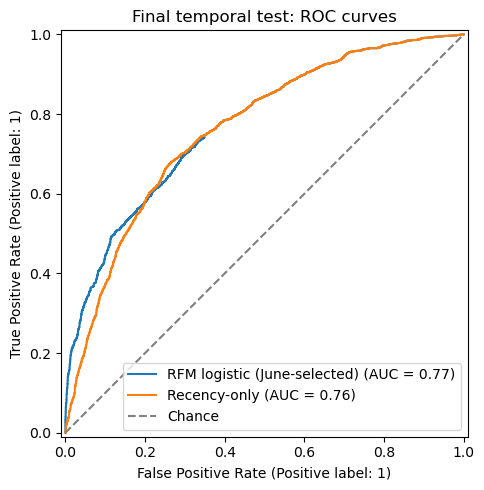

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(test['Repeat90d'], (final_test_prob >= 0.5).astype(int),
                                        display_labels=['No repeat', 'Repeat'], ax=ax, cmap='Blues', colorbar=False)
ax.set_title('RFM logistic regression: final test confusion matrix')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(test['Repeat90d'], final_test_prob, name='RFM logistic (June-selected)', ax=ax)
RocCurveDisplay.from_predictions(test['Repeat90d'], recency_prob, name='Recency-only', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set_title('Final temporal test: ROC curves')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9. Repeat-purchase ranking by decile

Customers are ranked by predicted repeat probability to assess whether the highest-scored decile purchases more frequently than average. High repeat propensity alone is not a reason to offer a discount.

Test customers: 5281
Top-decile customers: 529
Overall 90-day repeat rate: 43.4%
Top-decile repeat rate: 90.9%
Top-decile lift over average: 2.10x


,Customers,ActualRepeatRate,MeanPredictedProbability
Decile,,,
1,529,0.909,0.814
2,528,0.688,0.604
3,528,0.623,0.477
4,528,0.453,0.350
5,528,0.470,0.314
6,528,0.347,0.197
7,528,0.328,0.144
8,528,0.254,0.135
9,528,0.170,0.117


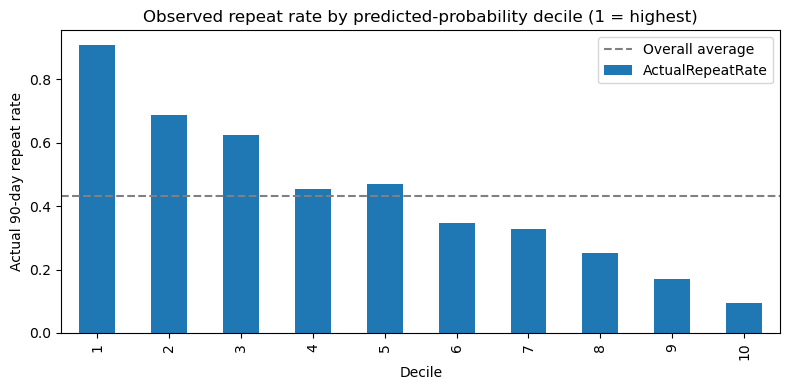

In [9]:
scored = test[['Customer ID', 'SnapshotDate', 'RecencyDays', 'Frequency',
               'MonetaryGBP', 'HistoricalSpendGBP', 'Repeat90d']].copy()
scored['PredictedRepeat90dRaw'] = test_prob
scored['PredictedRepeat90dAdjusted'] = test_adjusted
scored['PredictedRepeat90d'] = final_test_prob
scored['PredictedNoRepeat90d'] = 1 - final_test_prob
scored = scored.sort_values(['PredictedRepeat90d', 'Customer ID'], ascending=[False, True]).reset_index(drop=True)
number_top = int(np.ceil(0.10 * len(scored)))
top = scored.head(number_top)
overall_rate = scored['Repeat90d'].mean()
top_rate = top['Repeat90d'].mean()
print('Test customers:', len(scored))
print('Top-decile customers:', number_top)
print(f'Overall 90-day repeat rate: {overall_rate:.1%}')
print(f'Top-decile repeat rate: {top_rate:.1%}')
print(f'Top-decile lift over average: {top_rate / overall_rate:.2f}x')

scored['Decile'] = np.minimum(10, (np.floor(np.arange(len(scored)) * 10 / len(scored)) + 1)).astype(int)
deciles = scored.groupby('Decile').agg(Customers=('Customer ID', 'size'),
                                       ActualRepeatRate=('Repeat90d', 'mean'),
                                       MeanPredictedProbability=('PredictedRepeat90d', 'mean'))
display(deciles.round(3))
ax = deciles['ActualRepeatRate'].plot.bar(figsize=(8, 4))
ax.axhline(overall_rate, linestyle='--', color='gray', label='Overall average')
ax.set_title('Observed repeat rate by predicted-probability decile (1 = highest)')
ax.set_ylabel('Actual 90-day repeat rate')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Probability calibration

Predicted and observed repeat rates are compared across probability groups. Small groups may produce unstable estimates.

In [10]:
calibration = scored.copy()
calibration['ProbabilityBand'] = pd.cut(calibration['PredictedRepeat90d'],
                                       bins=np.linspace(0, 1, 6), include_lowest=True)
calibration_table = calibration.groupby('ProbabilityBand', observed=True).agg(
    Customers=('Customer ID', 'size'),
    AveragePrediction=('PredictedRepeat90d', 'mean'),
    ActualRepeatRate=('Repeat90d', 'mean'))
display(calibration_table.round(3))
print(f'Mean selected prediction: {scored.PredictedRepeat90d.mean():.3f}')
print(f'Observed repeat rate: {scored.Repeat90d.mean():.3f}')
print(f'Observed minus predicted: {100*(scored.Repeat90d.mean()-scored.PredictedRepeat90d.mean()):+.2f} percentage points')


,Customers,AveragePrediction,ActualRepeatRate
ProbabilityBand,,,
"(-0.001, 0.2]",2494,0.128,0.228
"(0.2, 0.4]",1290,0.330,0.453
"(0.4, 0.6]",651,0.512,0.651
"(0.6, 0.8]",585,0.691,0.793
"(0.8, 1.0]",261,0.881,0.954


Mean selected prediction: 0.324
Observed repeat rate: 0.434
Observed minus predicted: +10.94 percentage points


## 11. Segment association test

Pearson’s chi-square test compares repeat behavior among Champions and At Risk / High Value customers. Expected counts and the percentage-point difference support interpretation. This exploratory association assumes independent customer observations and does not establish causality.

In [11]:
from scipy.stats import chi2_contingency
segment_data = scored.merge(reference[['Customer ID', 'Segment']], on='Customer ID', validate='one_to_one')
groups = ['Champions', 'At Risk / High Value']
contingency = pd.crosstab(segment_data['Segment'], segment_data['Repeat90d']).reindex(index=groups, columns=[0, 1], fill_value=0)
display(contingency)
rates = contingency[1] / contingency.sum(axis=1)
gap_pp = 100 * (rates.iloc[0] - rates.iloc[1])
assert (contingency.sum(axis=0) > 0).all() and (contingency.sum(axis=1) > 0).all()
chi2, p_value, dof, expected = chi2_contingency(contingency, correction=False)
display(pd.DataFrame(expected, index=groups, columns=['No repeat', 'Repeat']).round(2))
print(f'Champions repeat rate: {rates.iloc[0]:.1%}')
print(f'At Risk / High Value repeat rate: {rates.iloc[1]:.1%}')
print(f'Repeat-rate gap: {gap_pp:+.2f} percentage points')
if expected.min() >= 5:
    print(f'Pearson chi-square={chi2:.3f}, df={dof}, p={p_value:.3g}')
else:
    print('Expected counts below 5; chi-square inference not reported.')
pd.DataFrame([{'ChampionsRepeatRate': rates.iloc[0], 'AtRiskRepeatRate': rates.iloc[1],
               'GapPercentagePoints': gap_pp, 'ChiSquare': chi2 if expected.min() >= 5 else np.nan,
               'PValue': p_value if expected.min() >= 5 else np.nan,
               'MinimumExpectedCount': expected.min()}]).to_csv(OUTPUT / '02_segment_repeat_test.csv', index=False)


Repeat90d,0,1
Segment,,
Champions,121,701
At Risk / High Value,189,207


,No repeat,Repeat
Champions,209.21,612.79
At Risk / High Value,100.79,295.21


Champions repeat rate: 85.3%
At Risk / High Value repeat rate: 52.3%
Repeat-rate gap: +33.01 percentage points
Pearson chi-square=153.455, df=1, p=3.05e-35


## 12. Export model results and customer scores

The historical test scores and evaluation tables support the retrospective targeting analysis in Notebook 03. They are not live campaign predictions.

In [12]:
results.to_csv(OUTPUT / '02_model_comparison.csv', index=False)
coef_table.to_csv(OUTPUT / '02_logistic_coefficients.csv', index=False)
snapshot_overview.to_csv(OUTPUT / '02_snapshot_overview.csv', index=False)
scored.to_csv(OUTPUT / '02_historical_test_customer_scores.csv', index=False)
deciles.to_csv(OUTPUT / '02_decile_performance.csv')
calibration_table.to_csv(OUTPUT / '02_calibration_table.csv')
print('Saved model comparison, coefficients, snapshot overview, historical customer scores, deciles and calibration table.')
print('Output folder:', OUTPUT.resolve())
pd.DataFrame([{'ValidationBrierRaw': validation_brier_raw, 'ValidationBrierAdjusted': validation_brier_adjusted, 'InterceptShift': intercept_shift, 'UsedAdjustment': USE_ADJUSTED, 'TestBrierRaw': brier_score_loss(test['Repeat90d'], test_prob), 'TestBrierAdjusted': brier_score_loss(test['Repeat90d'], test_adjusted)}]).to_csv(OUTPUT / '02_calibration_decision.csv', index=False)


Saved model comparison, coefficients, snapshot overview, historical customer scores, deciles and calibration table.
Output folder: C:\Users\user\Documents\Wright\Capstone\Capstone Project\retention-scoring-capstone\outputs


## 13. Model findings

The full RFM model achieved a test ROC AUC of approximately 0.775 and average precision of 0.741. The top decile had an observed repeat rate of 90.9%, about 2.10 times the overall rate. Frequency and monetary value were strongly correlated, so the negative conditional monetary coefficient does not imply that spending reduces loyalty.

## 14. Limitations

The adjusted mean test prediction was 32.4%, compared with an observed repeat rate of 43.4%. Seasonal changes are a plausible but unverified explanation for the temporal shift. Repeated customer snapshots are related, and positive purchases exclude matched-return reconciliation. The historical data contain no randomized offer exposure, so repeat propensity cannot establish incremental campaign response. The results may not generalize to current retail conditions.